In [1]:
from sklearn.datasets import load_digits
X, y = load_digits(return_X_y=True)

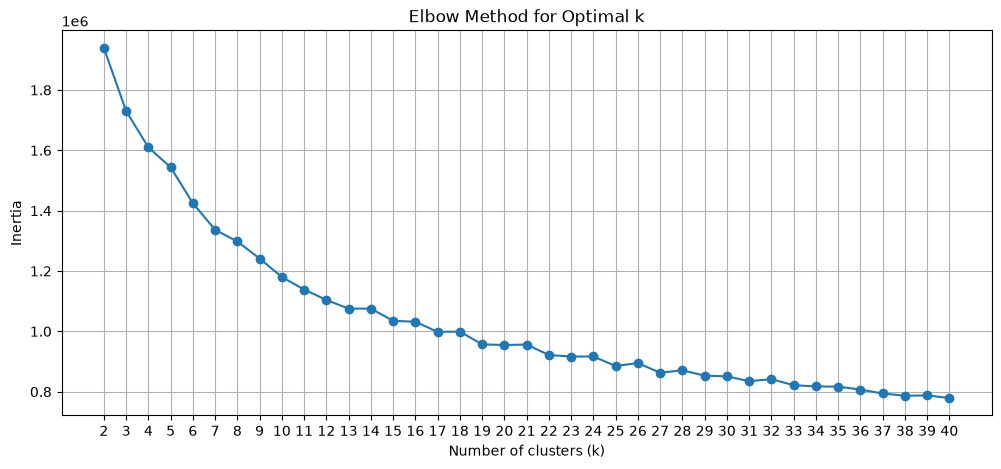

In [7]:
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

def plot_elbow(X, max_k=10):
  inertias = []
  ks = range(2, max_k+1)
  for k in ks:
    kmeans = KMeans(n_clusters=k).fit(X)
    inertias.append(kmeans.inertia_)
  plt.figure(figsize=(12,5))
  plt.plot(ks, inertias, marker='o')
  plt.xlabel('Number of clusters (k)')
  plt.ylabel('Inertia')
  plt.title('Elbow Method for Optimal k')
  plt.xticks(ks)
  plt.grid()
  plt.show()

plot_elbow(X, max_k=40)

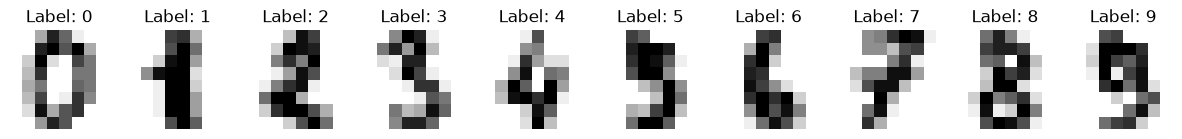

In [9]:
fig, axes = plt.subplots(1, 10, figsize=(15, 3))
for ax, image, label in zip(axes, X, y):
    ax.imshow(image.reshape(8, 8), cmap='gray_r')
    ax.set_title(f'Label: {label}')
    ax.axis('off')
plt.show()

In [11]:
from sklearn.linear_model import RidgeClassifier
from sklearn.model_selection import cross_val_score

model = RidgeClassifier()
scores = cross_val_score(model, X, y, cv=5)
print(f'Cross-validation scores: {scores}')
print(f'Mean accuracy: {scores.mean():.4f}')

Cross-validation scores: [0.92777778 0.83888889 0.90529248 0.92200557 0.84679666]
Mean accuracy: 0.8882


In [12]:
from sklearn.pipeline import Pipeline

pipeline = Pipeline([
    ('kmeans', KMeans(n_clusters=32)),
    ('ridge', RidgeClassifier())
])
scores_pipeline = cross_val_score(pipeline, X, y, cv=5)
print(f'Cross-validation scores with KMeans: {scores_pipeline}')
print(f'Mean accuracy with KMeans: {scores_pipeline.mean():.4f}')

Cross-validation scores with KMeans: [0.95277778 0.86388889 0.93036212 0.94707521 0.89972145]
Mean accuracy with KMeans: 0.9188


In [14]:
import optuna

def objective(trial):
    n_clusters = trial.suggest_int('n_clusters', 2, 128)
    pipeline = Pipeline([
        ('kmeans', KMeans(n_clusters=n_clusters)),
        ('ridge', RidgeClassifier())
    ])
    scores = cross_val_score(pipeline, X, y, cv=5)
    return scores.mean()

study = optuna.create_study(direction='maximize')
study.optimize(objective, n_trials=50)

print(f'Best number of clusters: {study.best_params["n_clusters"]}')
print(f'Best accuracy: {study.best_value:.4f}')

/home/boldt/projects/aulasml/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
[I 2026-10-05 21:04:48,776] A new study created in memory with name: no-name-071d2c9c-f15a-4dd9-a801-561f62b545d1
[I 2026-10-05 21:04:49,622] Trial 0 finished with value: 0.9560445682451254 and parameters: {'n_clusters': 97}. Best is trial 0 with value: 0.9560445682451254.
[I 2026-10-05 21:04:50,305] Trial 1 finished with value: 0.951590838749613 and parameters: {'n_clusters': 84}. Best is trial 0 with value: 0.9560445682451254.
[I 2026-10-05 21:04:50,974] Trial 2 finished with value: 0.9560507582791706 and parameters: {'n_clusters': 100}. Best is trial 2 with value: 0.9560507582791706.
[I 2026-10-05 21:04:51,172] Trial 3 finished with value: 0.9076338594862271 and parameters: {'n_clusters': 23}. Best is trial 2 with valu

Best number of clusters: 118
Best accuracy: 0.9616


In [15]:
model = Pipeline([
    ('kmeans', KMeans(n_clusters=study.best_params['n_clusters'])),
    ('ridge', RidgeClassifier())
])
scores = cross_val_score(model, X, y, cv=5)
print(f'Cross-validation scores with best KMeans: {scores}')
print(f'Mean accuracy with best KMeans: {scores.mean():.4f}')

Cross-validation scores with best KMeans: [0.96388889 0.93055556 0.97493036 0.99164345 0.93593315]
Mean accuracy with best KMeans: 0.9594


In [16]:
model = Pipeline([
    ('kmeans', KMeans(n_clusters=250)),
    ('ridge', RidgeClassifier())
])
scores = cross_val_score(model, X, y, cv=5)
print(f'Cross-validation scores with 250 clusters: {scores}')
print(f'Mean accuracy with 250 clusters: {scores.mean():.4f}')

Cross-validation scores with 250 clusters: [0.97777778 0.94444444 0.98050139 0.98328691 0.93871866]
Mean accuracy with 250 clusters: 0.9649
